In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/property-project/properties.csv")
print(df.shape)
df.head()

(203874, 26)


,ad_title,ad_description,details,slug,title,type,price,timestamp,posted_date,deactivation_date,...,is_doorstep_delivery,is_dsd_applicable,is_member,is_authorized_dealer,is_featured_member,is_verified,membership_level,member_since,properties,user
0,apartment for sale in colombo 05 | ikman,Project: Aquaria by Access Residencies.\n\nSq....,"Bedrooms: 3, Bathrooms: 2",apartment-for-sale-in-colombo-05-for-sale-colo...,apartment for sale in colombo 05,for_sale,"Rs 59,500,000",16 Feb 2:38 pm,2023-02-16T14:38:34+05:30,2022-01-31T04:43:32.000Z,...,False,False,True,False,False,True,plus,October 2016,"{'Address': 'kirimandala mawatha, colombo 05.'...",2a36021370cdd0f50da19f64d17ad43be687d48568ec12...
1,Land for Sale in Kurunegala | ikman.lk,à·à·à¶à·âà¶»à¶ºà·à¶±à· à¶¯à·à¶ºà·à¶«...,15.0 perches,land-for-sale-in-kurunegala-for-sale-kurunegal...,Land for Sale in Kurunegala,for_sale,"Rs 50,000 per perch",10 Nov 12:06 pm,2022-11-10T12:06:19+05:30,2022-07-30T09:30:41.000Z,...,False,False,True,False,False,False,premium,April 2017,"{'Address': 'kurunegala,malkaduwawa', 'Land ty...",f917ed789e936ada5530694ede4edde85fdb53f739c5f6...
2,Land for Sale in Kelaniya | ikman,Good Residential Bare Land in Kelaniya\nLocate...,18.5 perches,land-for-sale-in-kelaniya-for-sale-gampaha-766,Land for Sale in Kelaniya,for_sale,"Rs 1,600,000 per perch",30 Jan 8:54 am,2023-01-30T08:54:35+05:30,2022-07-30T09:31:26.000Z,...,False,False,True,False,False,True,premium,August 2016,"{'Address': 'Dalugama, Kelaniya', 'Land type':...",147c45b684bfeae3e3ffb0397b126d4e67392ad600e254...
3,Land for Sale in Kelaniya | ikman,Good Residential bare land in Kelaniya\nLocate...,12.0 perches,land-for-sale-in-kelaniya-for-sale-gampaha-765,Land for Sale in Kelaniya,for_sale,"Rs 1,700,000 per perch",30 Jan 8:54 am,2023-01-30T08:54:29+05:30,2022-07-30T09:24:20.000Z,...,False,False,True,False,False,True,premium,August 2016,"{'Address': 'Off Kohalwila Road, Dalugama - Ke...",147c45b684bfeae3e3ffb0397b126d4e67392ad600e254...
4,Semi Luxury House for Sale in Kadawatha | ikman,Semi Luxury House in Kadawatha\nLocated at Pin...,"Bedrooms: 5, Bathrooms: 4",semi-luxury-house-for-sale-in-kadawatha-for-sa...,Semi Luxury House for Sale in Kadawatha,for_sale,"Rs 55,000,000",30 Jan 8:54 am,2023-01-30T08:54:09+05:30,2021-10-03T08:33:36.000Z,...,False,False,True,False,False,True,premium,August 2016,"{'Address': 'Pinthaliya Road, Kadawatha', 'Bed...",147c45b684bfeae3e3ffb0397b126d4e67392ad600e254...


In [ ]:
print(df.columns.tolist())
print(df["type"].value_counts())
print(df.isnull().sum())

['ad_title', 'ad_description', 'details', 'slug', 'title', 'type', 'price', 'timestamp', 'posted_date', 'deactivation_date', 'category', 'parent_category', 'location', 'geo_region', 'area', 'is_delivery_free', 'is_doorstep_delivery', 'is_dsd_applicable', 'is_member', 'is_authorized_dealer', 'is_featured_member', 'is_verified', 'membership_level', 'member_since', 'properties', 'user']
type
for_sale    168971
for_rent     33376
to_rent        837
to_buy         690
Name: count, dtype: int64
ad_title                    0
ad_description              2
details                  1527
slug                        0
title                       0
type                        0
price                    1562
timestamp                   6
posted_date                 6
deactivation_date           6
category                    0
parent_category             0
location                    0
geo_region                  0
area                        0
is_delivery_free            0
is_doorstep_delivery      

In [ ]:
df_sale = df[df["type"] == "for_sale"].copy()
print(df_sale.shape)
print(df_sale["category"].value_counts())
print(df_sale[["location", "geo_region", "area"]].head(10))
print(df_sale["price"].head(15))

(168971, 26)
category
Land For Sale                     82123
Houses For Sale                   51890
Land                              27046
Apartments For Sale                5177
Commercial Properties For Sale     2700
New Projects                         35
Name: count, dtype: int64
           location geo_region                                area
0         Colombo 5      LK-11     {'id': 1506, 'name': 'Colombo'}
1   Kurunegala City      LK-61  {'id': 1674, 'name': 'Kurunegala'}
2          Kelaniya      LK-12     {'id': 1577, 'name': 'Gampaha'}
3          Kelaniya      LK-12     {'id': 1577, 'name': 'Gampaha'}
4         Kadawatha      LK-12     {'id': 1577, 'name': 'Gampaha'}
5            Horana         LK    {'id': 1620, 'name': 'Kalutara'}
6            Horana         LK    {'id': 1620, 'name': 'Kalutara'}
7          Matugama         LK    {'id': 1620, 'name': 'Kalutara'}
9          Dehiwala      LK-11     {'id': 1506, 'name': 'Colombo'}
10     Talawatugoda      LK-11     {'id': 

In [ ]:
pd.set_option("display.float_format", "{:,.0f}".format)

df_sale["price_num"] = (
    df_sale["price"]
    .str.replace(",", "", regex=False)
    .str.extract(r"(\d+\.?\d*)")[0]
    .astype(float)
)
df_sale["is_per_perch"] = df_sale["price"].str.contains("per perch", na=False)

print(df_sale["price_num"].describe())
print(pd.crosstab(df_sale["category"], df_sale["is_per_perch"]))

count           168,929
mean         25,560,624
std       2,200,518,161
min                   6
25%             425,000
50%           2,000,000
75%          22,500,000
max     900,000,002,100
Name: price_num, dtype: float64
is_per_perch                    False  True 
category                                    
Apartments For Sale              5177      0
Commercial Properties For Sale   2700      0
Houses For Sale                 51890      0
Land                             5868  21178
Land For Sale                   17651  64472
New Projects                       35      0


In [ ]:
keep = ["Land For Sale", "Land", "Houses For Sale", "Apartments For Sale"]
df_sale = df_sale[df_sale["category"].isin(keep)].copy()

df_sale["property_type"] = df_sale["category"].replace({
    "Land For Sale": "Land",
    "Land": "Land",
    "Houses For Sale": "House",
    "Apartments For Sale": "Apartment",
})

print(df_sale.shape)
print(df_sale["property_type"].value_counts())

for t in ["Land", "House", "Apartment"]:
    print("\n---", t, "---")
    print(df_sale.loc[df_sale["property_type"] == t, "details"].dropna().sample(8, random_state=1).tolist())

(166236, 29)
property_type
Land         109169
House         51890
Apartment      5177
Name: count, dtype: int64

--- Land ---
['10.0 perches', '90.0 perches', '6.5 perches', '160.0 perches', '9.0 perches', '15.1 perches', '25.0 perches', '6.0 perches']

--- House ---
['Bedrooms: 3, Bathrooms: 3', 'Bedrooms: 4, Bathrooms: 2', 'Bedrooms: 4, Bathrooms: 4', 'Bedrooms: 4, Bathrooms: 2', 'Bedrooms: 2, Bathrooms: 2', 'Bedrooms: 6, Bathrooms: 4', 'Bedrooms: 4, Bathrooms: 4', 'Bedrooms: 4, Bathrooms: 1']

--- Apartment ---
['Bedrooms: 5, Bathrooms: 4', 'Bedrooms: 2, Bathrooms: 2', 'Bedrooms: 2, Bathrooms: 2', 'Bedrooms: 4, Bathrooms: 3', 'Bedrooms: 2, Bathrooms: 2', 'Bedrooms: 2, Bathrooms: 2', 'Bedrooms: 2, Bathrooms: 1', 'Bedrooms: 3, Bathrooms: 2']


In [ ]:
df_sale["perches"] = df_sale["details"].str.extract(r"([\d.]+)\s*perches")[0].astype(float)
df_sale["bedrooms"] = df_sale["details"].str.extract(r"Bedrooms:\s*(\d+)")[0].astype(float)
df_sale["bathrooms"] = df_sale["details"].str.extract(r"Bathrooms:\s*(\d+)")[0].astype(float)

df_sale["district"] = df_sale["area"].astype(str).str.extract(r"'name':\s*'([^']+)'")[0]

df_sale["total_price"] = df_sale["price_num"]
mask = df_sale["is_per_perch"]
df_sale.loc[mask, "total_price"] = df_sale.loc[mask, "price_num"] * df_sale.loc[mask, "perches"]

print(df_sale.groupby("property_type")[["perches", "bedrooms", "bathrooms", "total_price"]].apply(lambda g: g.isnull().sum()))
print(df_sale["district"].value_counts().head(10))
print(df_sale.groupby("property_type")["total_price"].describe())

               perches  bedrooms  bathrooms  total_price
property_type                                           
Apartment         5177         0          0            0
House            51890         0          0            2
Land              1559    109169     109169          247
district
Colombo         89096
Gampaha         31563
Kalutara        17386
Kurunegala       5731
Galle            4675
Kandy            3087
Matara           2391
Hambantota       1991
Anuradhapura     1905
Ratnapura        1895
Name: count, dtype: int64
                count       mean           std   min        25%        50%  \
property_type                                                                
Apartment       5,177 99,042,647 1,187,622,477 6,500 33,000,000 52,000,000   
House          51,888 58,380,407 3,951,134,545     7 17,000,000 28,500,000   
Land          108,922 14,367,689   450,348,972     0  2,500,000  4,000,000   

                     75%             max  
property_type             

In [ ]:
df_clean = df_sale.dropna(subset=["total_price"]).copy()

# Land walata perches nathnam ain karanna
df_clean = df_clean[~((df_clean["property_type"] == "Land") & (df_clean["perches"].isnull()))]

# Hama type ekakatama wadima podi 1% saha wadima loku 1% ain karanna
low = df_clean.groupby("property_type")["total_price"].transform(lambda s: s.quantile(0.01))
high = df_clean.groupby("property_type")["total_price"].transform(lambda s: s.quantile(0.99))
df_clean = df_clean[(df_clean["total_price"] >= low) & (df_clean["total_price"] <= high)].copy()

print("Before:", df_sale.shape[0], "After:", df_clean.shape[0])
print(df_clean.groupby("property_type")["total_price"].describe())

Before: 166236 After: 161422
                count       mean        std       min        25%        50%  \
property_type                                                                 
Apartment       5,076 68,540,514 64,688,951 5,500,000 33,500,000 52,000,000   
House          50,883 38,588,105 35,394,735 3,150,000 17,500,000 28,500,000   
Land          105,463  8,458,143 14,992,402   750,000  2,500,000  3,990,000   

                     75%         max  
property_type                         
Apartment     80,000,000 594,594,000  
House         46,000,000 225,000,000  
Land           7,650,000 150,000,000  


In [ ]:
before = df_clean.shape[0]

df_clean = df_clean.drop_duplicates(
    subset=["ad_title", "ad_description", "details", "price", "location", "user"]
)

print("Before:", before, "After:", df_clean.shape[0])

# Model ekata ona columns witharak ganna
final_cols = ["property_type", "location", "district", "geo_region",
              "perches", "bedrooms", "bathrooms", "total_price", "posted_date"]
df_final = df_clean[final_cols].copy()

df_final.to_csv("/content/drive/MyDrive/property-project/clean_properties.csv", index=False)
print(df_final.shape)
print(df_final.isnull().sum())

Before: 161422 After: 151687
(151687, 9)
property_type         0
location              0
district              0
geo_region            0
perches           50679
bedrooms         101008
bathrooms        101008
total_price           0
posted_date           5
dtype: int64


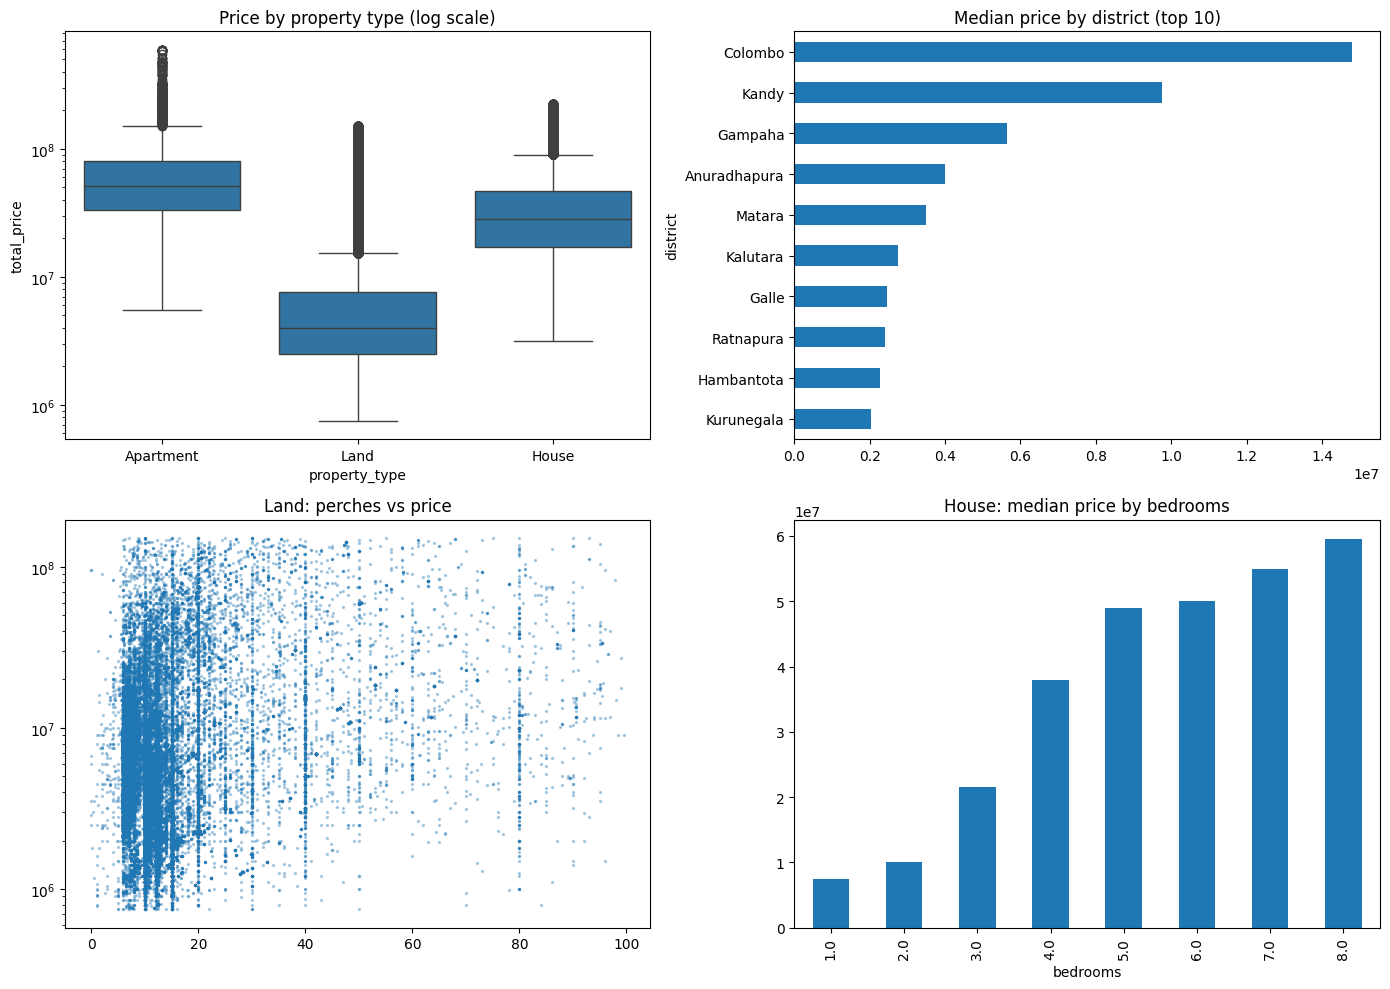

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

df = pd.read_csv("/content/drive/MyDrive/property-project/clean_properties.csv")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1) Property type walata price distribution (log scale)
sns.boxplot(data=df, x="property_type", y="total_price", ax=axes[0, 0])
axes[0, 0].set_yscale("log")
axes[0, 0].set_title("Price by property type (log scale)")

# 2) District walata median price (top 10 districts)
top = df["district"].value_counts().head(10).index
med = df[df["district"].isin(top)].groupby("district")["total_price"].median().sort_values()
med.plot(kind="barh", ax=axes[0, 1])
axes[0, 1].set_title("Median price by district (top 10)")

# 3) Land: perches vs price
land = df[(df["property_type"] == "Land") & (df["perches"] < 100)]
axes[1, 0].scatter(land["perches"], land["total_price"], s=2, alpha=0.3)
axes[1, 0].set_yscale("log")
axes[1, 0].set_title("Land: perches vs price")

# 4) House: bedrooms walata median price
house = df[(df["property_type"] == "House") & (df["bedrooms"] <= 8)]
house.groupby("bedrooms")["total_price"].median().plot(kind="bar", ax=axes[1, 1])
axes[1, 1].set_title("House: median price by bedrooms")

plt.tight_layout()
plt.show()

In [ ]:
for t in ["House", "Apartment", "Land"]:
    print("\n=====", t, "=====")
    for s in df_clean[df_clean["property_type"] == t]["properties"].head(3):
        print(s)
        print()


===== House =====
{'Address': 'Pinthaliya Road, Kadawatha', 'Bedrooms': '5', 'Bathrooms': '4', 'House size': '3,000.0 sqft', 'Land size': '27.5 perches'}

{'Address': 'kadawatha Road', 'Bedrooms': '4', 'Bathrooms': '4', 'House size': '3,000.0 sqft', 'Land size': '8.75 perches'}

{'Address': 'Off Temple Road, Mount Lavinia', 'Bedrooms': '4', 'Bathrooms': '2', 'House size': '5,600.0 sqft', 'Land size': '20.0 perches'}


===== Apartment =====
{'Address': 'kirimandala mawatha, colombo 05.', 'Bedrooms': '3', 'Bathrooms': '2', 'Size': '1,363 sqft'}

{'Address': 'Duplication Rd,Colombo 03', 'Bedrooms': '3', 'Bathrooms': '3', 'Size': '1,581 sqft'}

{'Address': 'Blue Ocean Apartment - Colombo 03', 'Bedrooms': '3', 'Bathrooms': '2', 'Size': '1,440 sqft'}


===== Land =====
{'Address': 'kurunegala,malkaduwawa', 'Land type': 'Commercial, Residential', 'Land size': '15.0 perches'}

{'Address': 'Dalugama, Kelaniya', 'Land type': 'Residential, Other', 'Land size': '18.5 perches'}

{'Address': 'Off K

In [ ]:
p = df_clean["properties"].astype(str)

def to_number(series):
    return series.str.replace(",", "", regex=False).astype(float)

# Floor area (sqft): House eke 'House size', Apartment eke 'Size'
house_sqft = to_number(p.str.extract(r"'House size':\s*'([\d,\.]+)\s*sqft")[0])
apt_sqft = to_number(p.str.extract(r"'Size':\s*'([\d,\.]+)\s*sqft")[0])
df_clean["floor_area_sqft"] = house_sqft.fillna(apt_sqft)

# Land size (perches): House saha Land deka walata
prop_perches = to_number(p.str.extract(r"'Land size':\s*'([\d,\.]+)\s*perches")[0])
df_clean["land_perches"] = df_clean["perches"].fillna(prop_perches)

# Land type: Land walata witharak
df_clean["land_type"] = p.str.extract(r"'Land type':\s*'([^']+)'")[0]

# Balamu
print(df_clean.groupby("property_type")[["floor_area_sqft", "land_perches"]].apply(lambda g: g.isnull().sum()))
print(df_clean.groupby("property_type")["floor_area_sqft"].describe())
print(df_clean["land_type"].value_counts().head(8))

# Aluth file eka save karanna
final_cols = ["property_type", "location", "district", "geo_region",
              "land_perches", "floor_area_sqft", "bedrooms", "bathrooms",
              "land_type", "total_price", "posted_date"]
df_final = df_clean[final_cols].copy()
df_final.to_csv("/content/drive/MyDrive/property-project/clean_properties_v2.csv", index=False)
print(df_final.shape)

               floor_area_sqft  land_perches
property_type                               
Apartment                    0          4595
House                        0           103
Land                    101008             0
               count  mean   std  min   25%   50%   75%     max
property_type                                                  
Apartment      4,595 1,433   978    0 1,050 1,280 1,596  30,500
House         46,084 2,656 5,894    0 1,527 2,353 3,200 900,000
Land               0   NaN   NaN  NaN   NaN   NaN   NaN     NaN
land_type
Residential                                     36949
Commercial, Residential                         19476
Commercial, Residential, Other                  17016
Residential, Other                              16854
Agricultural, Commercial, Residential, Other     3562
Agricultural, Residential, Other                 2183
Agricultural, Commercial, Residential            1218
Agricultural, Residential                        1114
Name: count, 

In [ ]:
import pandas as pd
pd.set_option("display.float_format", "{:,.1f}".format)

df = pd.read_csv("/content/drive/MyDrive/property-project/clean_properties_v2.csv")
before = len(df)

built = df["property_type"].isin(["House", "Apartment"])

# 1) Sqft 200 ta adu ads ain karanna
df = df[~(built & (df["floor_area_sqft"] < 200))]

# 2) Sqft eke wadima loku 1% ain karanna (type ekakatama)
cap = df.groupby("property_type")["floor_area_sqft"].transform(lambda s: s.quantile(0.99))
df = df[~(df["property_type"].isin(["House", "Apartment"]) & (df["floor_area_sqft"] > cap))]

# 3) Perches 0 ain karanna, saha wadima loku 1% ain karanna
df = df[~(df["land_perches"] <= 0)]
cap2 = df.groupby("property_type")["land_perches"].transform(lambda s: s.quantile(0.99))
df = df[~(df["land_perches"] > cap2)]

print("Before:", before, "After:", len(df))

cols = ["floor_area_sqft", "land_perches", "bedrooms", "bathrooms"]
print(df.groupby("property_type")[cols].agg(["min", "median", "max"]).T)

df.to_csv("/content/drive/MyDrive/property-project/clean_properties_final.csv", index=False)

Before: 151687 After: 149635
property_type           Apartment   House  Land
floor_area_sqft min         309.0   200.0   NaN
                median    1,275.0 2,338.0   NaN
                max       5,000.0 8,000.0   NaN
land_perches    min           NaN     0.1   0.1
                median        NaN    10.0  10.0
                max           NaN    67.0 120.0
bedrooms        min           1.0     1.0   NaN
                median        3.0     4.0   NaN
                max          10.0    10.0   NaN
bathrooms       min           1.0     1.0   NaN
                median        2.0     3.0   NaN
                max          10.0    10.0   NaN


In [ ]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/property-project/clean_properties_final.csv")

df["is_residential"] = df["land_type"].str.contains("Residential", na=False).astype(int)
df["is_commercial"] = df["land_type"].str.contains("Commercial", na=False).astype(int)
df["is_agricultural"] = df["land_type"].str.contains("Agricultural", na=False).astype(int)

# Model ekata denna final columns
final_cols = ["property_type", "district", "land_perches", "floor_area_sqft",
              "bedrooms", "bathrooms", "is_residential", "is_commercial",
              "is_agricultural", "total_price"]
df_model = df[final_cols].copy()

print(df_model.isnull().sum())
print(df_model.head())

df_model.to_csv("/content/drive/MyDrive/property-project/model_ready.csv", index=False)
print("Saved:", df_model.shape)

property_type           0
district                0
land_perches         4643
floor_area_sqft    100017
bedrooms           100017
bathrooms          100017
is_residential          0
is_commercial           0
is_agricultural         0
total_price             0
dtype: int64
  property_type    district  land_perches  floor_area_sqft  bedrooms  \
0     Apartment     Colombo           NaN          1,363.0       3.0   
1          Land  Kurunegala          15.0              NaN       NaN   
2          Land     Gampaha          18.5              NaN       NaN   
3          Land     Gampaha          12.0              NaN       NaN   
4         House     Gampaha          27.5          3,000.0       5.0   

   bathrooms  is_residential  is_commercial  is_agricultural  total_price  
0        2.0               0              0                0 59,500,000.0  
1        NaN               1              1                0    750,000.0  
2        NaN               1              0                0 29,60

Train the model

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

df = pd.read_csv("/content/drive/MyDrive/property-project/model_ready.csv")

num_cols = ["land_perches", "floor_area_sqft", "bedrooms", "bathrooms"]
df[num_cols] = df[num_cols].fillna(0)

df["log_price"] = np.log1p(df["total_price"])

df_encoded = pd.get_dummies(df, columns=["property_type", "district"], drop_first=True)

X = df_encoded.drop(columns=["total_price", "log_price"])
y = df_encoded["log_price"]

#  Train/test split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Train rows:", X_train.shape[0], "Test rows:", X_test.shape[0])
print("Total features:", X_train.shape[1])

Train rows: 119708 Test rows: 29927
Total features: 33


In [ ]:
# 1) Baseline: Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

# 2) Better model: Random Forest
rf = RandomForestRegressor(n_estimators=200, max_depth=15, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

# 3) Compare Results
def show_results(name, y_true, y_pred):
    y_true_actual = np.expm1(y_true)
    y_pred_actual = np.expm1(y_pred)

    mae = mean_absolute_error(y_true_actual, y_pred_actual)
    r2 = r2_score(y_true, y_pred)
    print(f"{name}: MAE = Rs {mae:,.0f}   R² = {r2:.3f}")

show_results("Linear Regression", y_test, lr_pred)
show_results("Random Forest", y_test, rf_pred)

Linear Regression: MAE = Rs 8,461,722   R² = 0.703
Random Forest: MAE = Rs 5,256,807   R² = 0.810


Feature importance

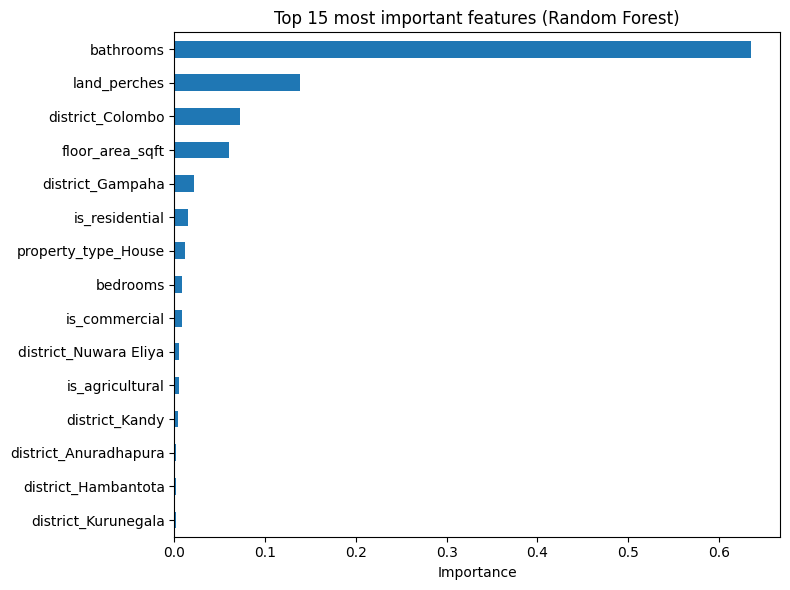

bathrooms               0.6
land_perches            0.1
district_Colombo        0.1
floor_area_sqft         0.1
district_Gampaha        0.0
is_residential          0.0
property_type_House     0.0
bedrooms                0.0
is_commercial           0.0
district_Nuwara Eliya   0.0
is_agricultural         0.0
district_Kandy          0.0
district_Anuradhapura   0.0
district_Hambantota     0.0
district_Kurunegala     0.0
dtype: float64


In [ ]:
import matplotlib.pyplot as plt

importances = pd.Series(rf.feature_importances_, index=X_train.columns)
top15 = importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(8, 6))
top15.sort_values().plot(kind="barh")
plt.title("Top 15 most important features (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

print(top15)

In [ ]:
types = df["property_type"]

for t in ["Land", "House", "Apartment"]:
    mask = (types == t).values
    sub_X = X[mask]
    sub_y = y[mask]
    if len(sub_X) < 50:
        continue
    Xtr, Xte, ytr, yte = train_test_split(sub_X, sub_y, test_size=0.2, random_state=42)
    m = RandomForestRegressor(n_estimators=150, max_depth=12, random_state=42, n_jobs=-1)
    m.fit(Xtr, ytr)
    pred = m.predict(Xte)
    mae_t = mean_absolute_error(np.expm1(yte), np.expm1(pred))
    r2_t = r2_score(yte, pred)
    print(f"{t}: rows={len(sub_X)}  MAE=Rs {mae_t:,.0f}  R²={r2_t:.3f}")
    imp = pd.Series(m.feature_importances_, index=sub_X.columns).sort_values(ascending=False).head(5)
    print(imp, "\n")

Land: rows=100017  MAE=Rs 4,008,531  R²=0.523
land_perches            0.5
district_Colombo        0.3
district_Gampaha        0.1
is_commercial           0.0
district_Nuwara Eliya   0.0
dtype: float64 

House: rows=45065  MAE=Rs 7,888,780  R²=0.797
bathrooms          0.6
floor_area_sqft    0.3
land_perches       0.1
district_Colombo   0.0
bedrooms           0.0
dtype: float64 

Apartment: rows=4553  MAE=Rs 16,048,788  R²=0.728
floor_area_sqft    0.8
bathrooms          0.1
bedrooms           0.1
district_Colombo   0.0
district_Gampaha   0.0
dtype: float64 



In [ ]:
house_df = df[df["property_type"] == "House"]
print(house_df[["floor_area_sqft", "bathrooms", "bedrooms", "total_price"]].corr()["total_price"])

floor_area_sqft   0.7
bathrooms         0.6
bedrooms          0.5
total_price       1.0
Name: total_price, dtype: float64


Save the Model

In [ ]:
import joblib

# Save the Model
joblib.dump(rf, "/content/drive/MyDrive/property-project/rf_model.pkl")

joblib.dump(list(X_train.columns), "/content/drive/MyDrive/property-project/model_columns.pkl")

print("Saved! Columns:", len(X_train.columns))

Saved! Columns: 33
